# Template

In [34]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [35]:
# Configure plotting defaults
pd.option_context('mode.use_inf_as_na', True)
plt.rcParams['figure.figsize'] = (10, 6)  # Adjust as needed
sns.set_style('whitegrid')

AttributeError: type object 'int' has no attribute '__main__'

In [11]:
def print_dunders(obj):
    """Prints all dunder (double underscore) attributes of an object."""
    for attr in dir(obj):
        if attr.startswith("__") and attr.endswith("__"):
            print(attr)

print_dunders(str)

__add__
__class__
__contains__
__delattr__
__dir__
__doc__
__eq__
__format__
__ge__
__getattribute__
__getitem__
__getnewargs__
__getstate__
__gt__
__hash__
__init__
__init_subclass__
__iter__
__le__
__len__
__lt__
__mod__
__mul__
__ne__
__new__
__reduce__
__reduce_ex__
__repr__
__rmod__
__rmul__
__setattr__
__sizeof__
__str__
__subclasshook__


## 1. Data Loading and Initial Inspection

In [36]:
# Load the dataset

filepath = "datasets/titanic.csv"

try:
    df = pd.read_csv(filepath, na_values=['', ' ', '  '], ) # parse_dates=["date_col"]
    print("Dataset loaded successfully.")
except FileNotFoundError:
    print("Error: Dataset file not found. Please check the path.")
    exit()  # Or handle the error differently

Dataset loaded successfully.


In [37]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [39]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [40]:
df.describe(include="object")

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Dooley, Mr. Patrick",male,347082,G6,S
freq,1,577,7,4,644


In [41]:
# Check for missing values (%)
df.isnull().sum() / len(df) * 100


PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64

## 2. Data Cleaning

In [42]:
# Clean age column by replacing NA with median age

df["Age"] = df["Age"].fillna(df["Age"].median())

In [56]:
# Clean cabin to be binary

df["Cabin"] = df["Cabin"].fillna(0)

df["Cabin"] = df["Cabin"] != 0

df.groupby("Pclass")["Cabin"].sum()


Pclass
1    176
2     16
3     12
Name: Cabin, dtype: int64

In [58]:
df["Embarked"].value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

In [44]:
# Handle duplicates (if any)
# print("\nNumber of duplicate rows:", df.duplicated().sum())
# df.drop_duplicates(inplace=True)

In [45]:
# Handle missing values (examples)
# df.fillna(0, inplace=True)  # Fill with 0
# df.fillna(df.mean(), inplace=True)  # Fill with mean
# df.dropna(inplace=True)  # Remove rows with any missing values
# df.fillna(method='ffill', inplace=True) # Forward fill

## 3. Exploratory Data Analysis (EDA)

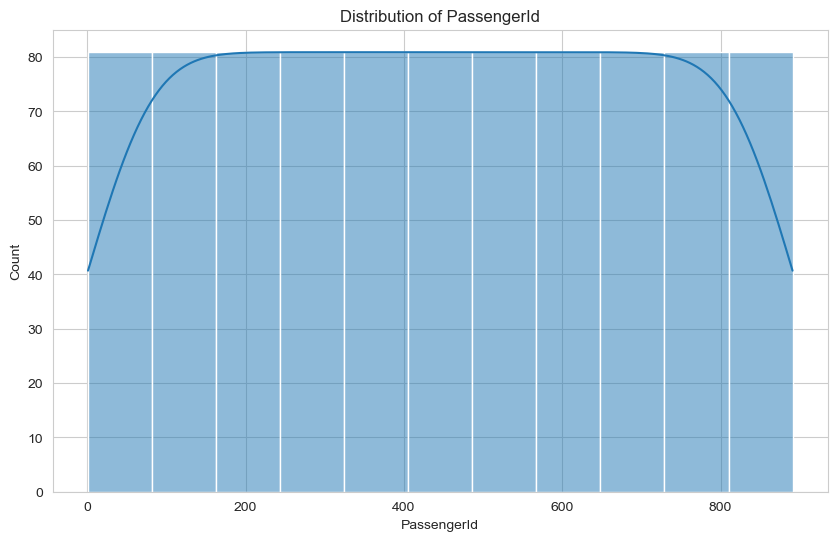

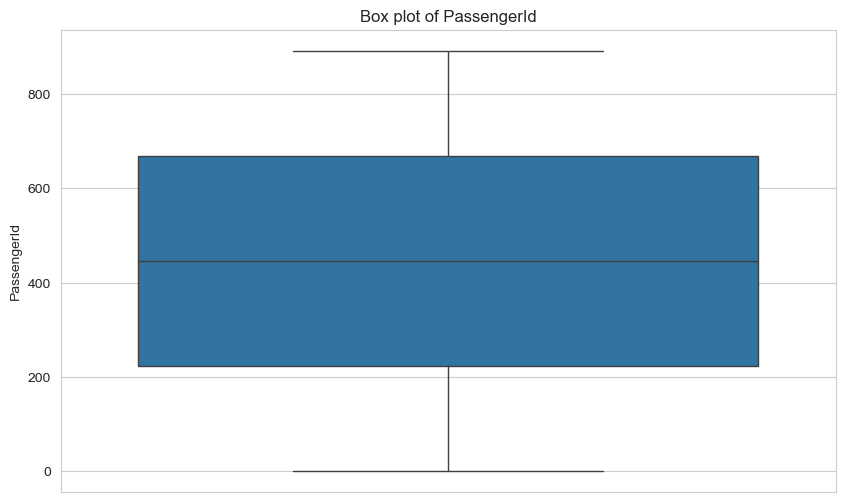

Summary statistics for PassengerId:
count    891.000000
mean     446.000000
std      257.353842
min        1.000000
25%      223.500000
50%      446.000000
75%      668.500000
max      891.000000
Name: PassengerId, dtype: float64


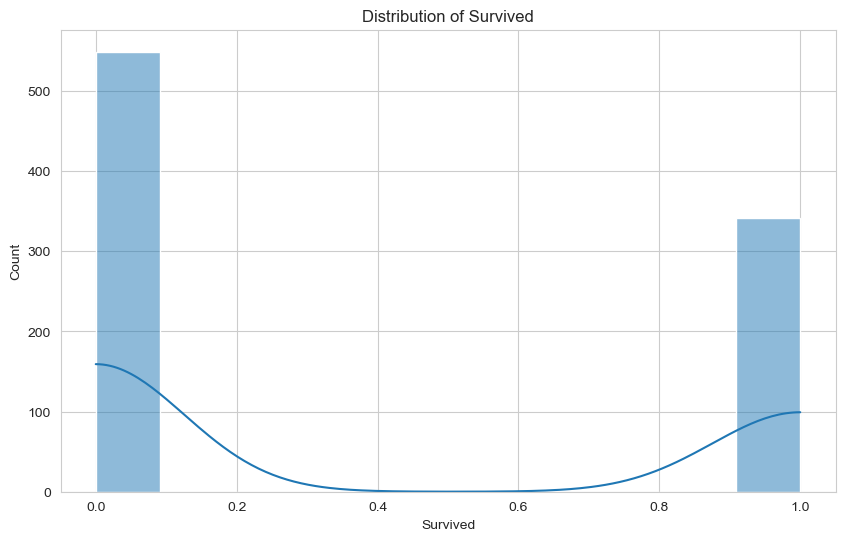

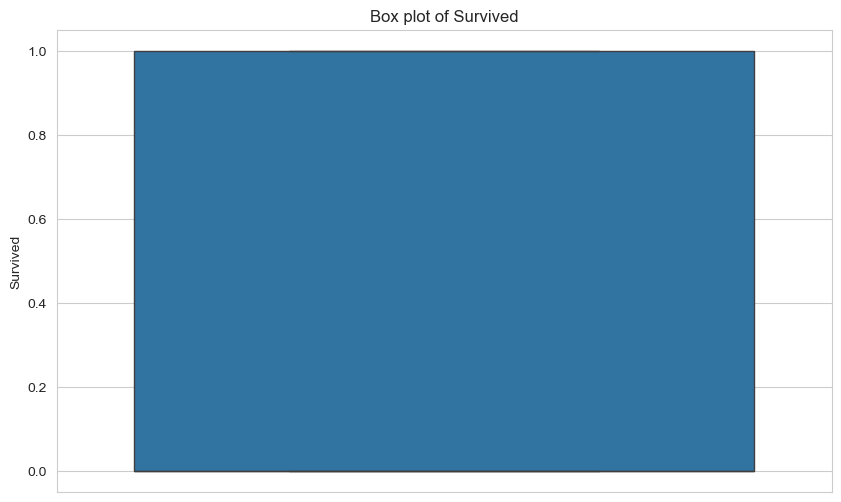

Summary statistics for Survived:
count    891.000000
mean       0.383838
std        0.486592
min        0.000000
25%        0.000000
50%        0.000000
75%        1.000000
max        1.000000
Name: Survived, dtype: float64


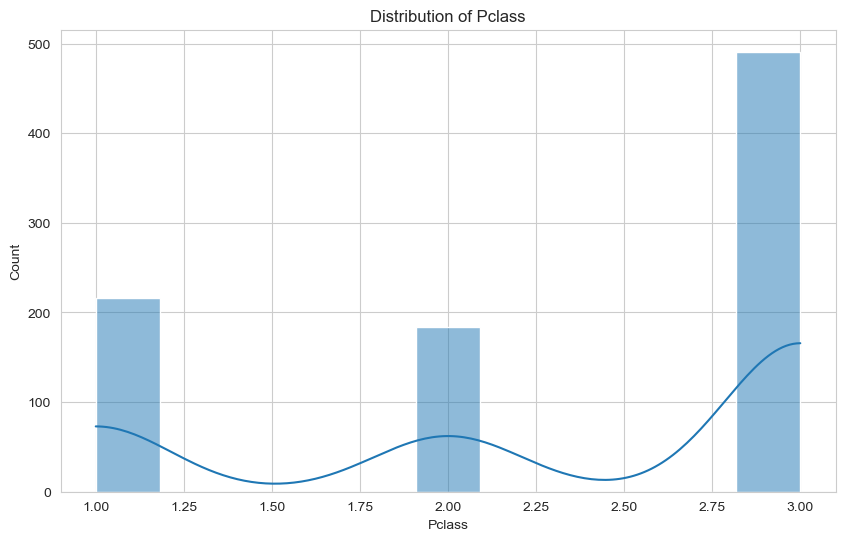

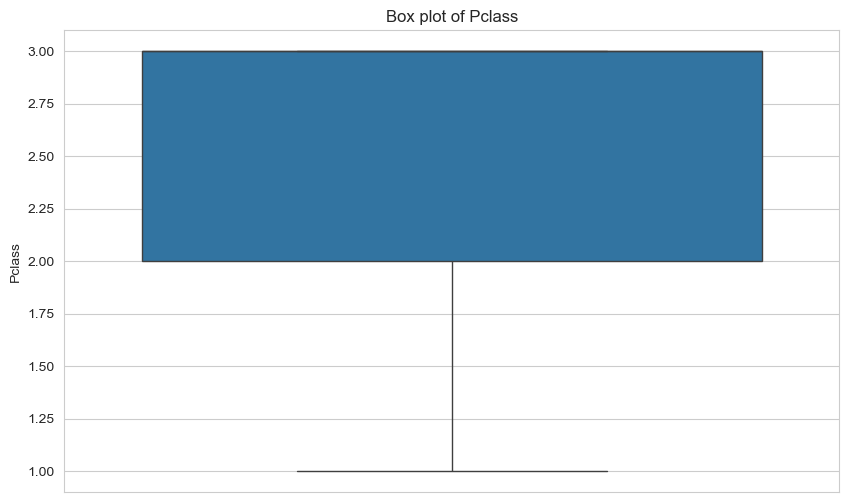

Summary statistics for Pclass:
count    891.000000
mean       2.308642
std        0.836071
min        1.000000
25%        2.000000
50%        3.000000
75%        3.000000
max        3.000000
Name: Pclass, dtype: float64


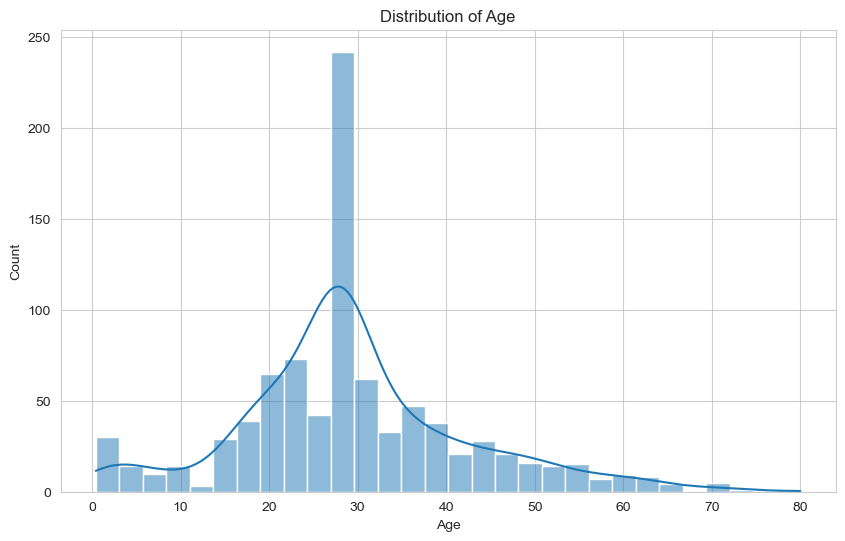

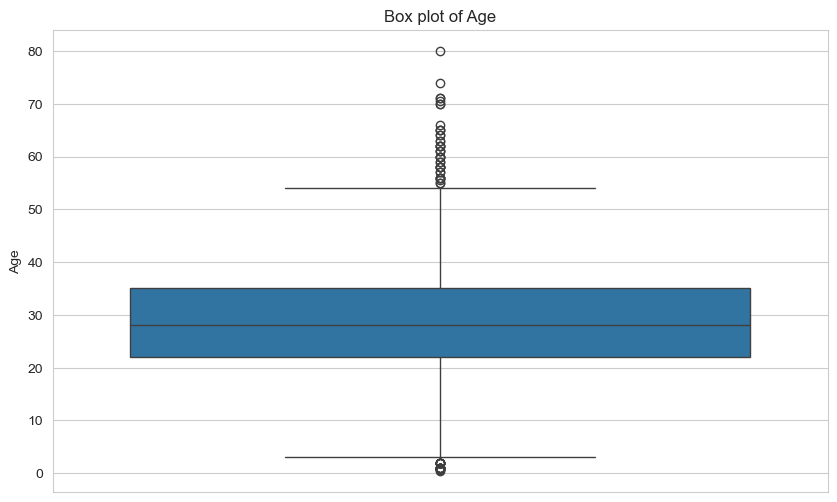

Summary statistics for Age:
count    891.000000
mean      29.361582
std       13.019697
min        0.420000
25%       22.000000
50%       28.000000
75%       35.000000
max       80.000000
Name: Age, dtype: float64


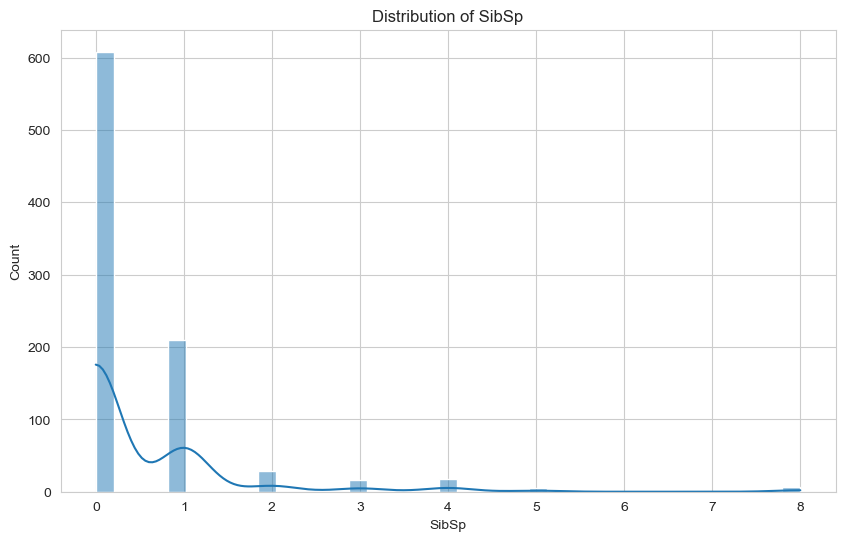

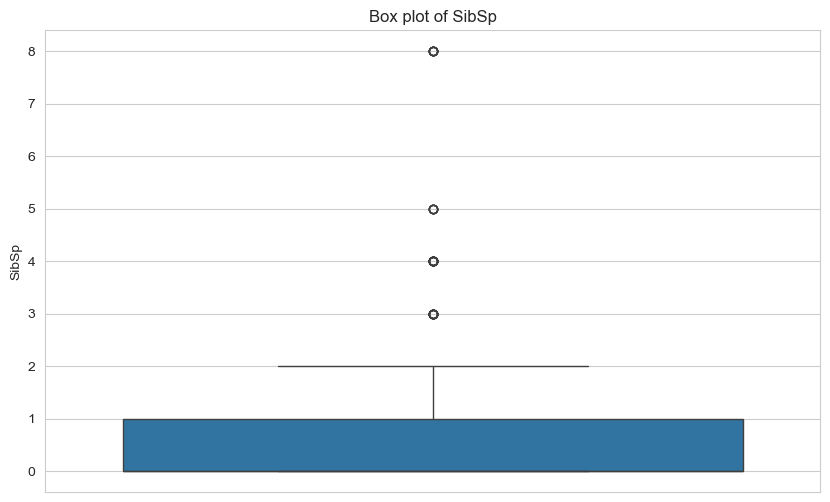

Summary statistics for SibSp:
count    891.000000
mean       0.523008
std        1.102743
min        0.000000
25%        0.000000
50%        0.000000
75%        1.000000
max        8.000000
Name: SibSp, dtype: float64


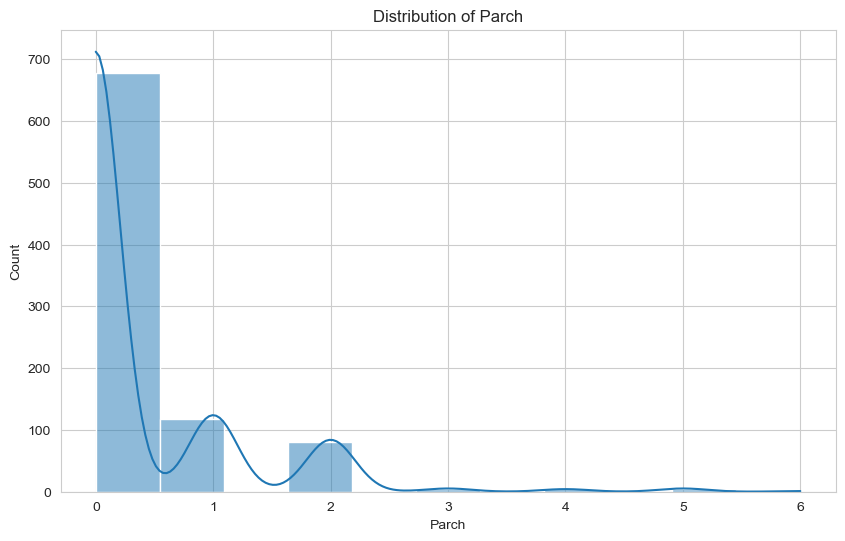

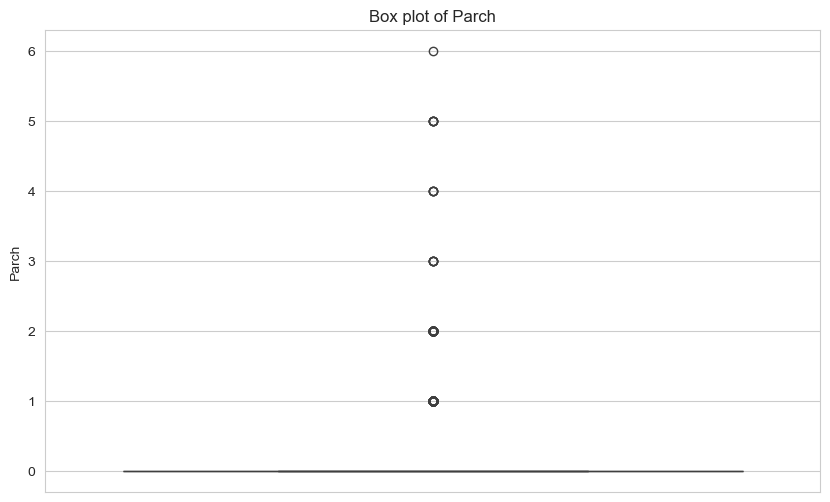

Summary statistics for Parch:
count    891.000000
mean       0.381594
std        0.806057
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        6.000000
Name: Parch, dtype: float64


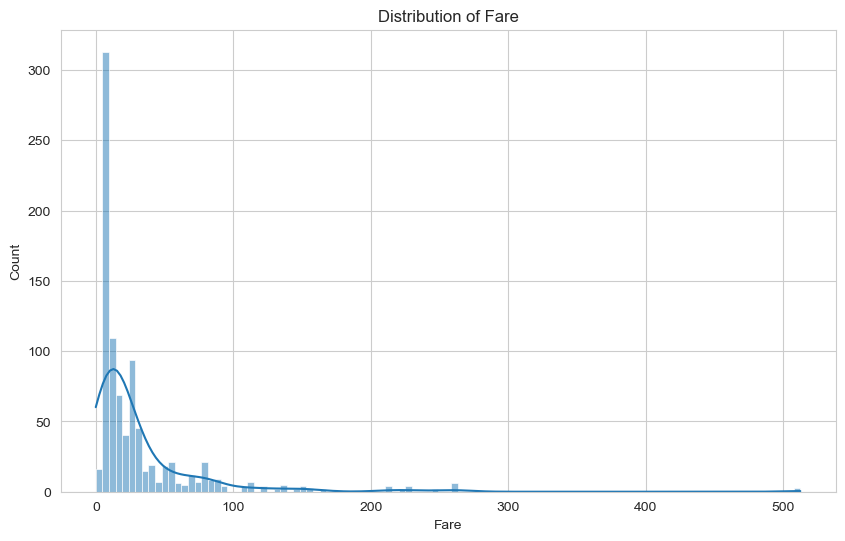

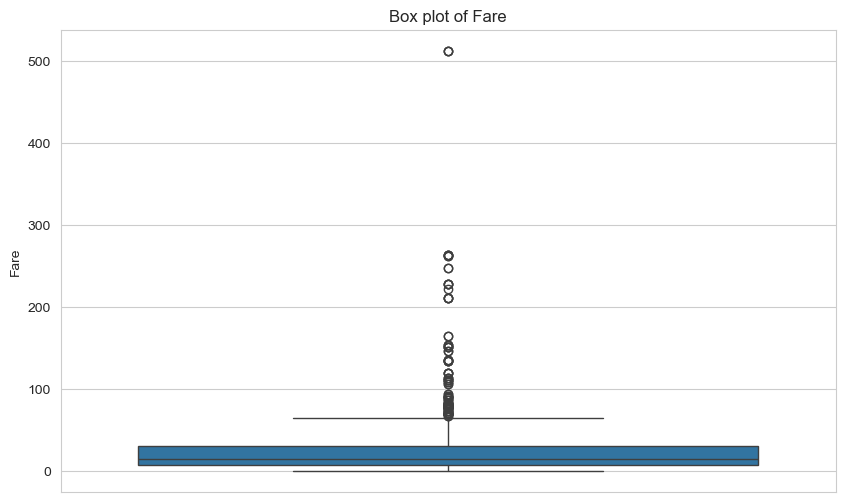

Summary statistics for Fare:
count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64


In [46]:
# Numerical features
for col in df.select_dtypes(include=np.number).columns:
    plt.figure()  # Create a new figure for each plot
    sns.histplot(df[col], kde=True)  # Histogram with KDE
    plt.title(f'Distribution of {col}')
    plt.show()

    plt.figure()
    sns.boxplot(y=df[col])  # Box plot
    plt.title(f'Box plot of {col}')
    plt.show()

    print(f"Summary statistics for {col}:")
    print(df[col].describe())

<Figure size 1000x600 with 0 Axes>

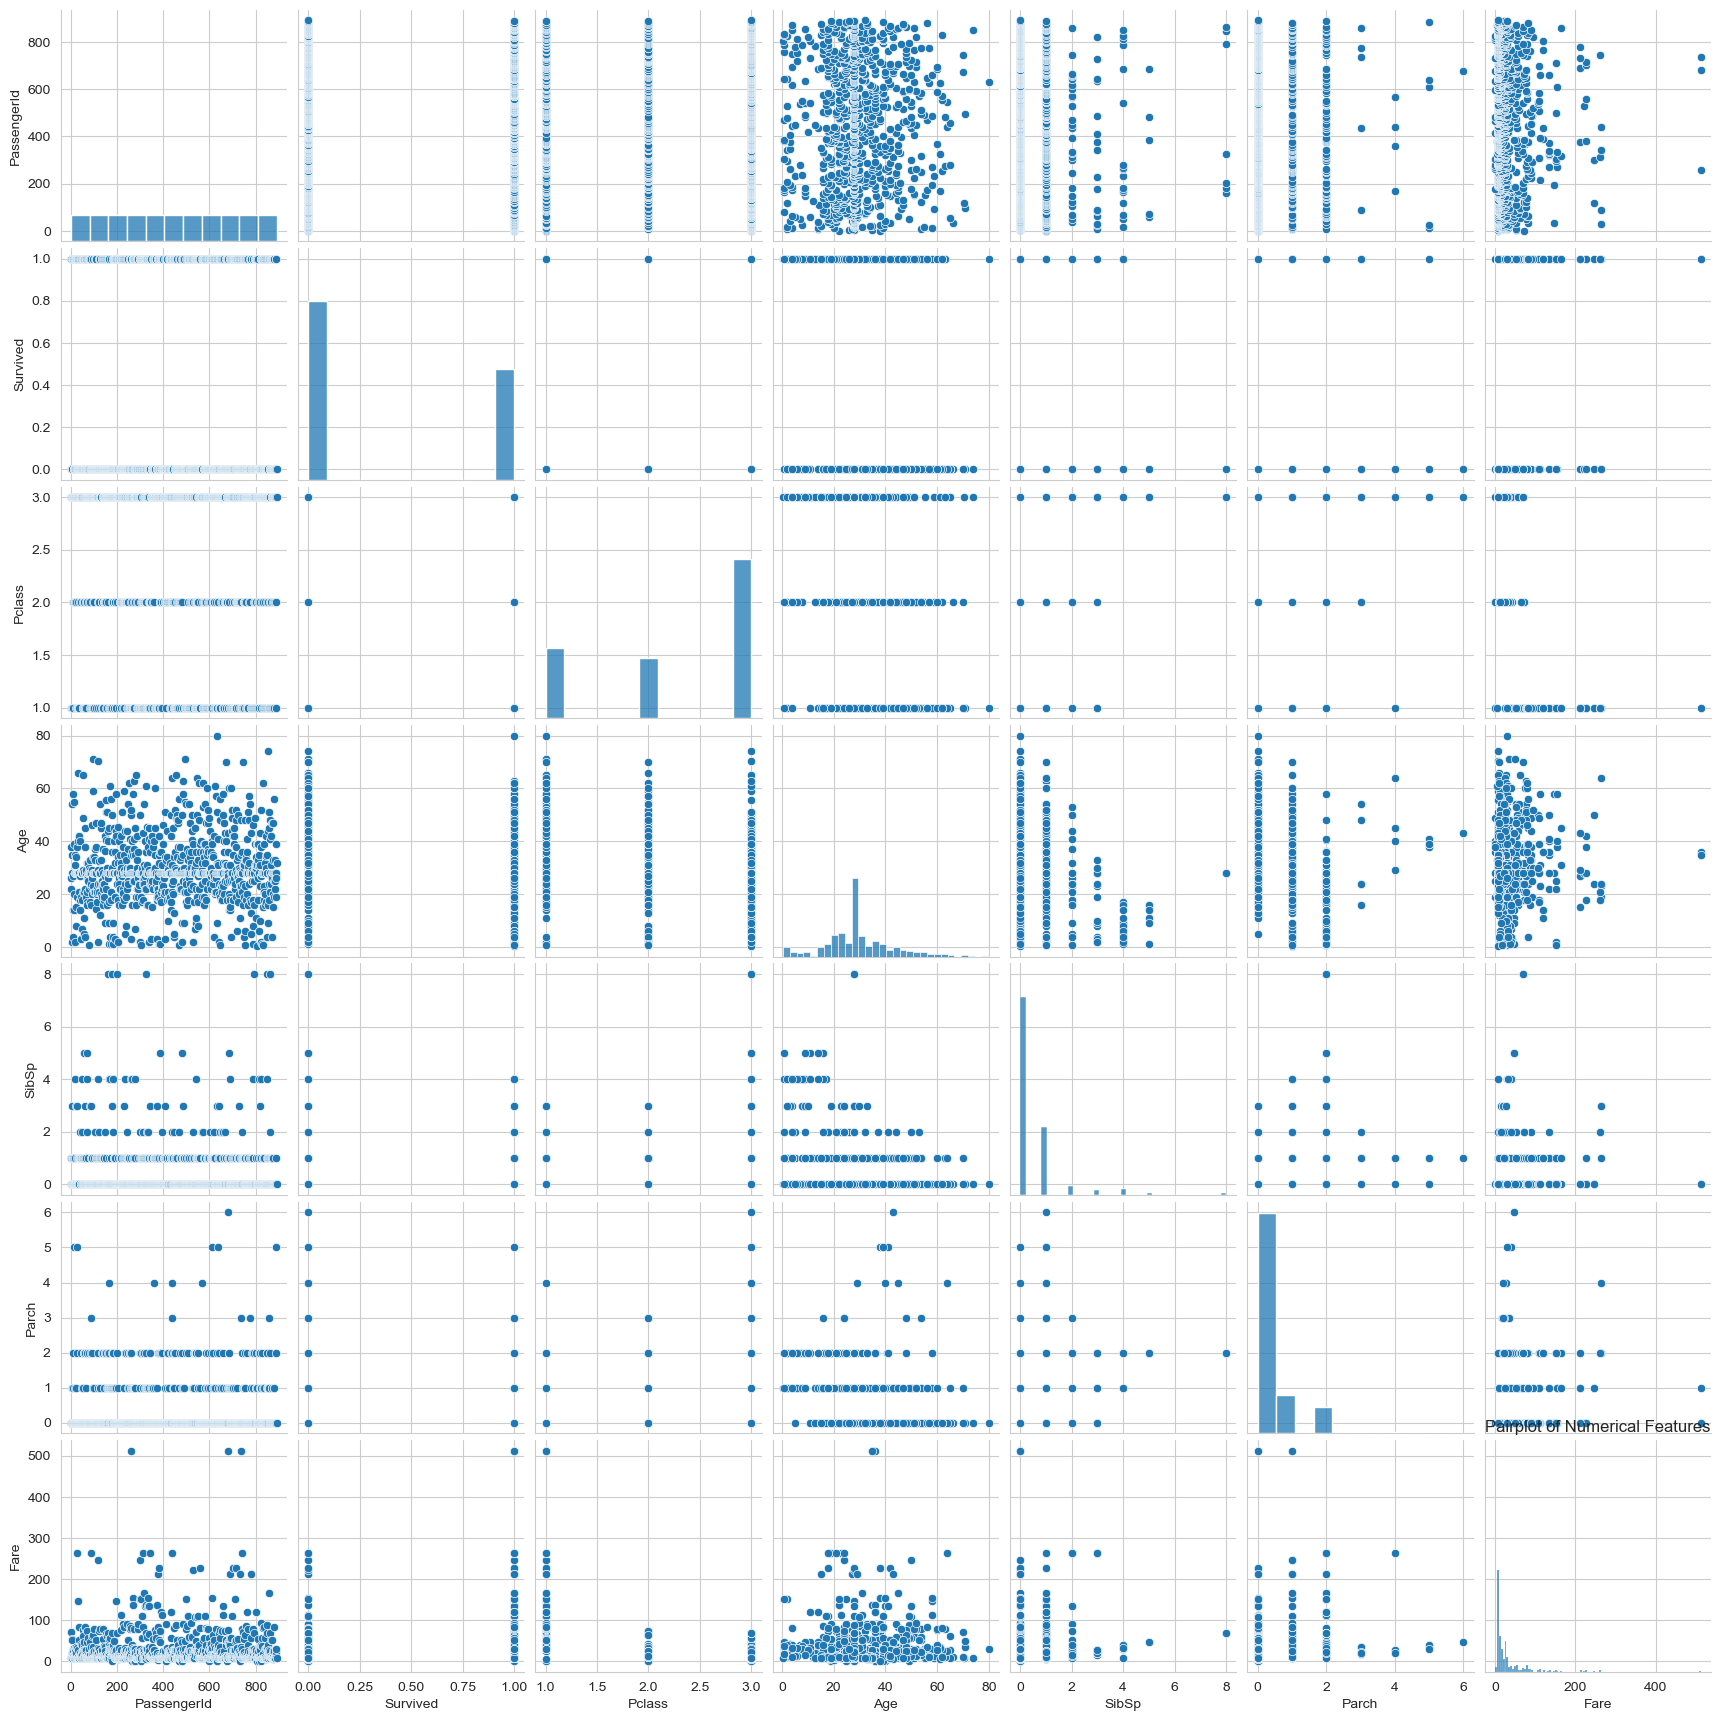

In [47]:
# Numerical vs. Numerical
plt.figure()
sns.pairplot(df.select_dtypes(include="number")) # Pairplot for all numerical features
plt.title('Pairplot of Numerical Features')
plt.show()

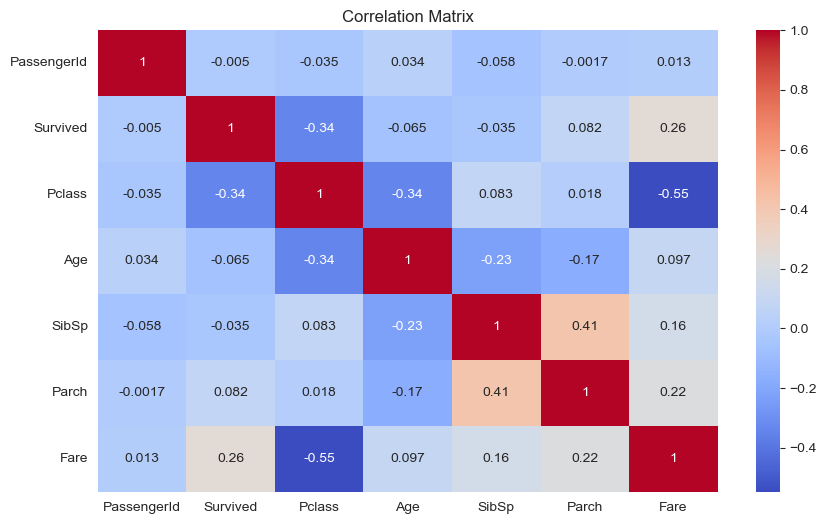

In [48]:
# Correlation matrix and heatmap
corr_matrix = df.select_dtypes(include=np.number).corr()

plt.title('Correlation Matrix')
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.show()